In [1]:
import torch
from torch import nn
from sklearn.datasets import load_digits, make_blobs
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import confusion_matrix
from pathlib import Path
%load_ext jupyter_black

import requests
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt

In [53]:
X, y = load_digits(return_X_y=True)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y)
X_train = torch.FloatTensor(X_train)
X_test = torch.FloatTensor(X_test)
y_train = torch.LongTensor(y_train)
y_test = torch.LongTensor(y_test)

In [54]:
model = nn.Sequential(
    nn.Linear(X_train.shape[1], 64),
    nn.ReLU(),
    nn.Linear(64, 32),
    nn.ReLU(),
    nn.Linear(32, len(torch.unique(y_train))),
    # nn.Softmax()
)


def train_model(model, X_train, y_train, loss_fn, epochs, optimizer):
    training_loss, test_loss = [], []
    for i in range(epochs):
        model.train()
        loss = loss_fn(model(X_train), y_train)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        training_loss.append(loss.item())

        model.eval()
        with torch.inference_mode():
            y_pred = model(X_test)
            test_loss.append(loss_fn(y_pred, y_test).item())

    plt.figure()
    plt.plot(training_loss, color="blue", label="Training Loss")
    plt.plot(test_loss, color="red", label="Test Loss")
    plt.legend()
    plt.xlabel("Epochs")
    plt.ylabel("Cross Entropy Loss")
    plt.title("Model Training and Testing")
    plt.show()

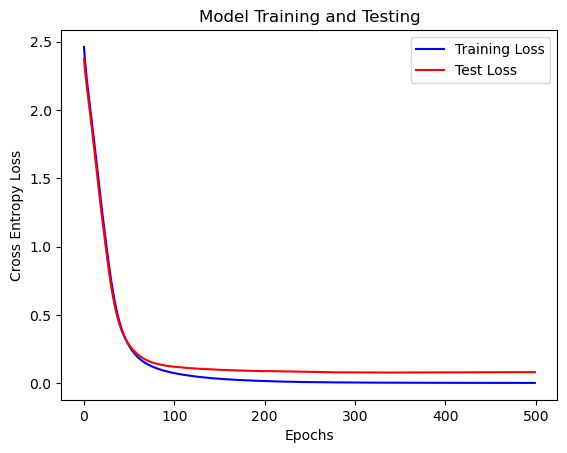

In [55]:
loss_fn = nn.CrossEntropyLoss()
epochs = 500
optimizer = torch.optim.Adam(params=model.parameters(), lr=1e-3)
train_model(model, X_train, y_train, loss_fn, epochs, optimizer)

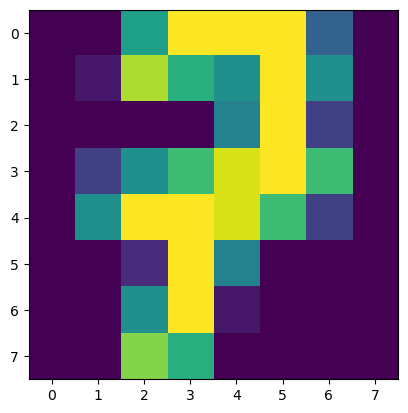

In [56]:
plt.figure()
plt.imshow(X_test[26].reshape(8, 8))
plt.show()

In [57]:
with torch.inference_mode():
    y_pred = model(X_test[26]).softmax(dim=0)
np.argmax(y_pred.detach().numpy())

np.int64(7)

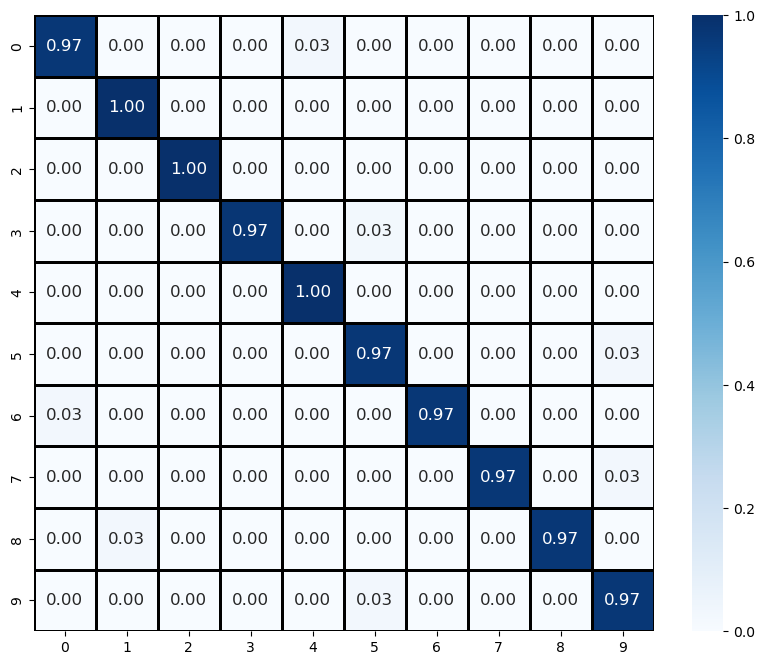

In [58]:
with torch.inference_mode():
    y_pred = model(X_test).softmax(dim=1).detach().numpy()
    y_prediction = np.argmax(y_pred, axis=1)

plt.figure(figsize=(10, 8))
sns.heatmap(
    data=confusion_matrix(y_test, y_prediction, normalize="true"),
    cmap="Blues",
    fmt=".2f",
    linecolor="k",
    linewidth=1,
    annot=True,
    annot_kws={"size": 12},
)
plt.show()

In [17]:
if Path("helper_functions.py").is_file():
    print("helper_functions.py already exists, skipping download")
else:
    print("Downloading helper_functions.py")
    request = requests.get(
        "https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/helper_functions.py"
    )
    with open("helper_functions.py", "wb") as f:
        f.write(request.content)

from helper_functions import plot_predictions, plot_decision_boundary

helper_functions.py already exists, skipping download


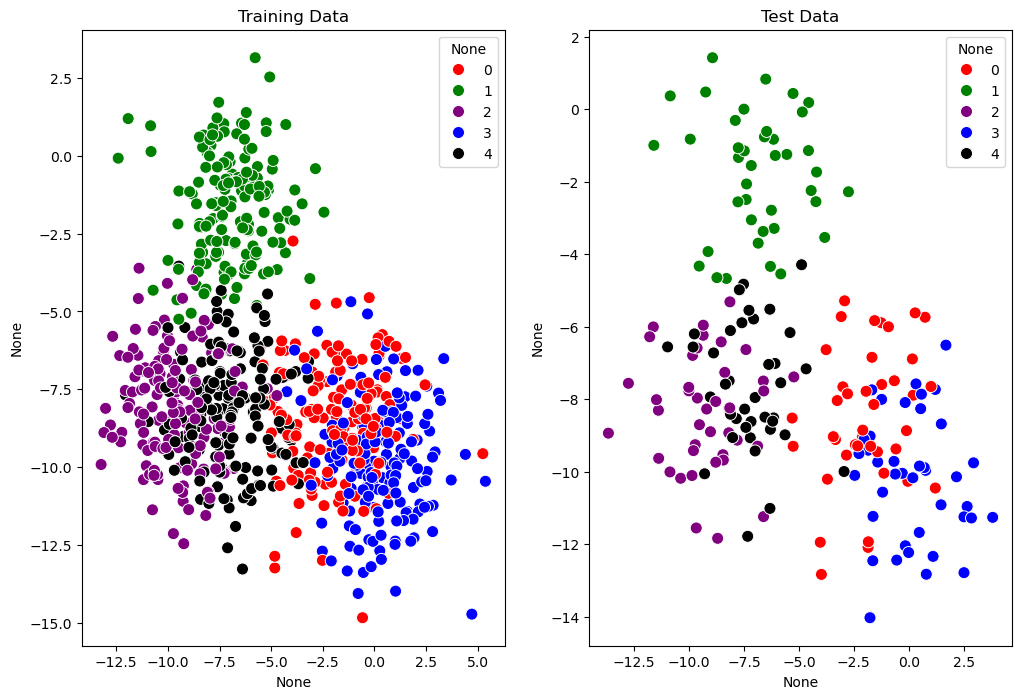

In [67]:
X, y = make_blobs(n_samples=1000, centers=5, cluster_std=1.7)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y)
X_train = torch.FloatTensor(X_train)
X_test = torch.FloatTensor(X_test)
y_train = torch.LongTensor(y_train)
y_test = torch.LongTensor(y_test)

fig, ax = plt.subplots(1, 2, figsize=(12, 8))
sns.scatterplot(
    x=X_train[:, 0],
    y=X_train[:, 1],
    hue=y_train,
    s=75,
    palette=["red", "green", "purple", "blue", "black"],
    ax=ax[0],
)
ax[0].set_title("Training Data")
sns.scatterplot(
    x=X_test[:, 0],
    y=X_test[:, 1],
    hue=y_test,
    s=75,
    palette=["red", "green", "purple", "blue", "black"],
    ax=ax[1],
)
ax[1].set_title("Test Data")
plt.show()

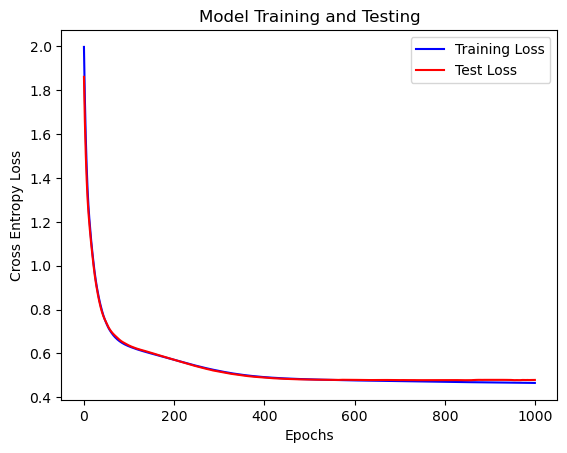

In [68]:
model_1 = nn.Sequential(
    nn.Linear(X_train.shape[1], 64),
    nn.ReLU(),
    nn.Linear(64, 32),
    nn.ReLU(),
    nn.Linear(32, len(torch.unique(y_train))),
)
loss_fn = nn.CrossEntropyLoss()
epochs = 1000
optimizer = torch.optim.Adam(params=model_1.parameters(), lr=1e-3)
train_model(model_1, X_train, y_train, loss_fn, epochs, optimizer)

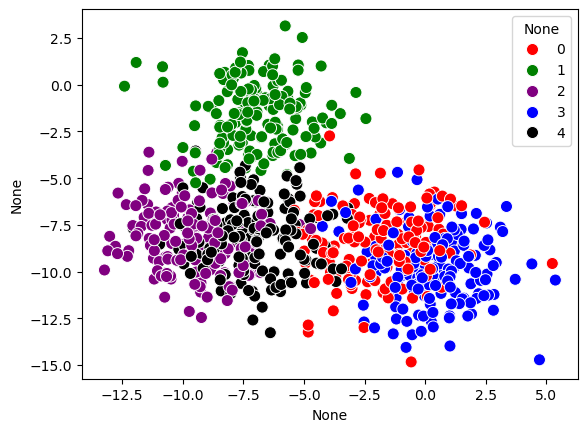

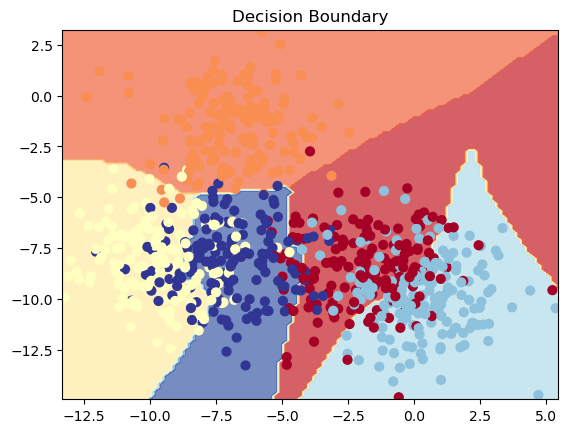

In [70]:
plt.figure()
sns.scatterplot(
    x=X_train[:, 0],
    y=X_train[:, 1],
    hue=y_train,
    s=75,
    palette=["red", "green", "purple", "blue", "black"],
)
plt.show()
plt.figure()
plt.title("Decision Boundary")
plot_decision_boundary(model_1, X_train, y_train)
plt.show()